In [1]:
from pca_utils import *

In [2]:
folder1 = Path(r"/mnt/c/users/helen/Desktop/190226/WT/foci2")
folder2 = Path(r"/mnt/c/users/helen/Desktop/190226/MGS3/foci2")

In [7]:
def import_data(folder, sample_name = None):
    dfs = []

    for file in sorted(folder.glob("*.csv")):
        temp = pd.read_csv(file)
        dfs.append(temp)

    df = pd.concat(dfs, ignore_index=True)

    df["sample"] = sample_name

    #print(df.shape)

    return df

In [8]:
df1 = import_data(folder1, sample_name = "WT")
df2 = import_data(folder2, sample_name = "MGS3")

dfs = [df1, df2]

df = pd.concat(dfs, ignore_index=True)

In [11]:
# Clean data
df.columns = df.columns.str.strip().str.lower()
df.iloc[:, 1:10] = df.iloc[:, 1:12].apply(pd.to_numeric, errors="coerce")
df = df.dropna()

In [14]:
df.head()

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity,image_id,sample
0,1,80.0,296.737500,293.562500,10.092530,0.713437,0.776699,40.384776,24.025000,50.0,13.0,0.616403,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,WT
1,2,45.0,141.444444,230.866667,7.569398,0.332226,0.849057,25.485281,30.000000,56.0,13.0,0.870650,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,WT
2,3,58.0,306.224138,147.000000,8.593480,0.737385,0.707317,33.142136,22.568966,41.0,13.0,0.663555,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,WT
3,4,22.0,84.045455,176.272727,5.292567,0.567142,0.846154,16.071068,16.500000,22.0,13.0,1.070393,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,WT
4,5,68.0,89.985294,178.161765,9.304853,0.404355,0.693878,42.384776,17.808823,30.0,13.0,0.475663,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,WT


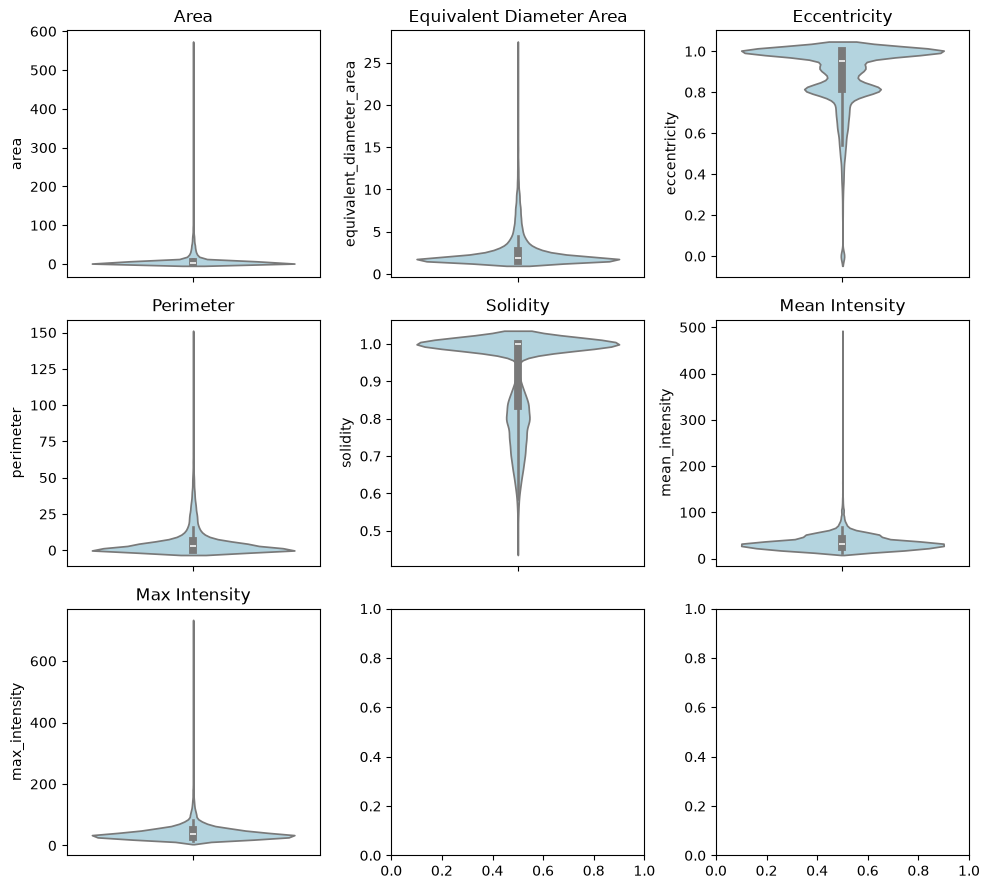

In [15]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


In [17]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

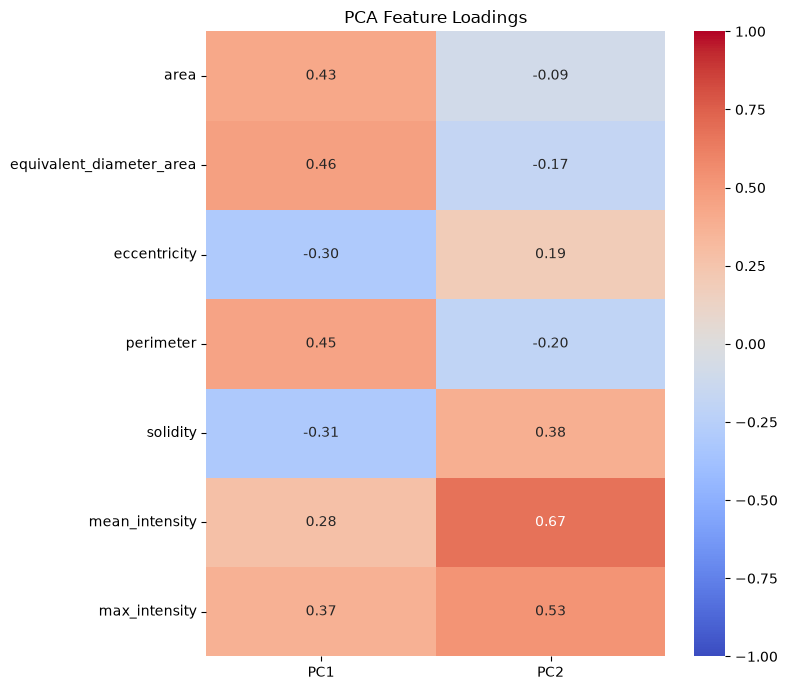

In [18]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [19]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS3    0.372216  0.358234
WT     -0.177401 -0.170737


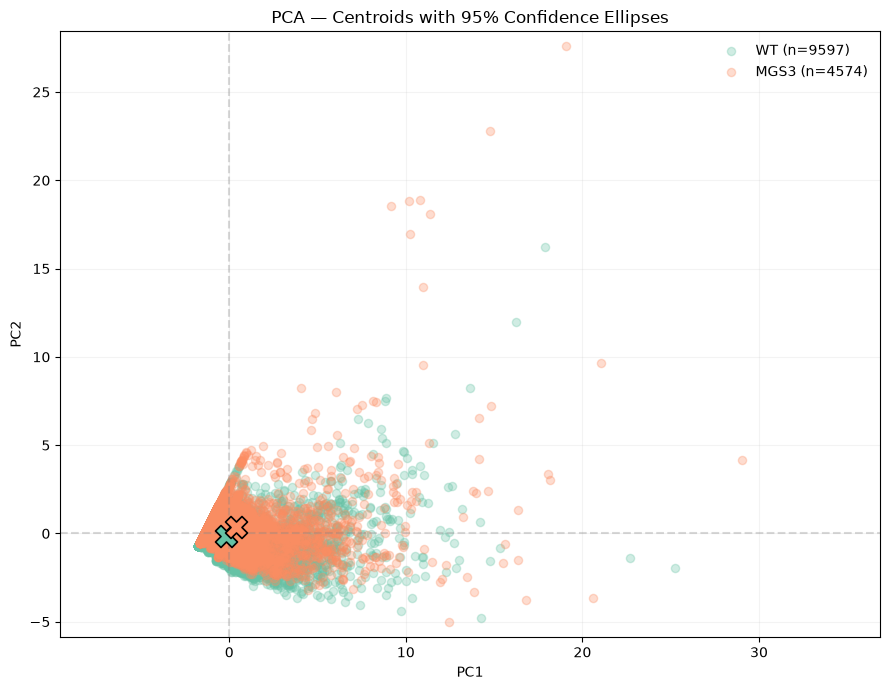

In [21]:
centroids = plot_pca_centroids_ci(
    pca_df,
    group_col="sample",
    confidence=0.95
)

In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats